# 04 — Area-Weighted Bimetallic Galvanic Mixed-Potential Analysis

This notebook demonstrates the Phase 2 bimetallic galvanic coupling solver (`corrosion_simulator.galvanic`):
1. Solving area-weighted current conservation via Brent's method (`brentq`) to find the steady-state **Mixed Potential ($E_{\text{galv}}$)**, **Galvanic Current Density ($i_{\text{galv}}$)**, **Acceleration Factor**, and accelerated **Initial Corrosion Rate ($\text{CR}_0$)** on the **Active Metal**.
2. Quantifying cathode-to-anode area ratio ($A_{\text{noble}} / A_{\text{active}}$) scaling across semiconductor interconnect/liner couples.
3. Propagating ML parameter uncertainty through the galvanic solver via physics-clipped Monte Carlo sampling.
4. Rendering overlaid bimetallic Tafel plots annotated with the $E_{\text{galv}}$ operating line and the shift from isolated $i_{\text{corr, active}}$ to coupled $i_{\text{galv}}$.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from corrosion_simulator import (
    HarmonizedDatabase,
    HybridMLPredictor,
    MLFeatureQuery,
    PolarizationParameters,
    plot_galvanic_tafel_overlay,
    propagate_galvanic_uncertainty_monte_carlo,
    solve_galvanic_couple,
    solve_galvanic_couple_from_database,
)

repo_root = Path(".").resolve()
raw_dir = repo_root / "data" / "raw"
db = HarmonizedDatabase.from_directory(raw_dir) if raw_dir.exists() else HarmonizedDatabase.from_seed()
print(f"Loaded HarmonizedDatabase: {len(db.electrochemical_database)} records across {db.electrochemical_database['metal'].nunique()} metals")


Loaded HarmonizedDatabase: 948 records across 8 metals


## 1. Benchmark Bimetallic Couple: Co (Active Metal) vs. Cu (Noble Metal)

We evaluate a Co/Cu couple in an acidic $\text{H}_2\text{O}_2$ + citric acid cleaning solution at $25\,^\circ\text{C}$ and verify that $E_{\text{galv}} \in (E_{\text{corr, active}}, E_{\text{corr, noble}})$ satisfies current conservation to $< 10^{-6}\,\mu\text{A/cm}^2$.


In [2]:
co_params = PolarizationParameters(
    Ecorr_V_SHE=-0.120,
    icorr_uA_cm2=12.0,
    beta_a_mV_dec=65.0,
    beta_c_mV_dec=120.0,
    metal="Co",
    solution_id="SOL_H2O2_CA_pH4",
    temperature_C=25.0,
)
cu_params = PolarizationParameters(
    Ecorr_V_SHE=0.285,
    icorr_uA_cm2=2.3,
    beta_a_mV_dec=60.0,
    beta_c_mV_dec=115.0,
    metal="Cu",
    solution_id="SOL_H2O2_CA_pH4",
    temperature_C=25.0,
)

res_1to1 = solve_galvanic_couple(co_params, cu_params, cathode_to_anode_area_ratio=1.0)
print(f"Active Metal: {res_1to1.active_metal} | Noble Metal: {res_1to1.noble_metal}")
print(f"E_galv = {res_1to1.mixed_potential_V_SHE:+.4f} V vs. SHE")
print(f"i_galv = {res_1to1.galvanic_current_density_uA_cm2:.3f} uA/cm2 (isolated i_corr = {co_params.icorr_uA_cm2:.3f} uA/cm2)")
print(f"Acceleration Factor = {res_1to1.acceleration_factor:.2f}x")
print(f"Uncoupled CR_0 = {res_1to1.uncoupled_cr_nm_min:.4f} nm/min -> Coupled CR_0 = {res_1to1.coupled_cr_nm_min:.4f} nm/min")
print(f"Current balance residual = {res_1to1.current_balance_residual_uA_cm2:.3e} uA/cm2")


Active Metal: Co | Noble Metal: Cu
E_galv = -0.0035 V vs. SHE
i_galv = 743.511 uA/cm2 (isolated i_corr = 12.000 uA/cm2)
Acceleration Factor = 61.96x
Uncoupled CR_0 = 0.2471 nm/min -> Coupled CR_0 = 15.3071 nm/min
Current balance residual = -7.958e-13 uA/cm2


## 2. Cathode-to-Anode Area Ratio ($A_{\text{noble}} / A_{\text{active}}$) Sweep

On patterned semiconductor wafers, exposed cathode-to-anode area ratios can vary from $0.1$ to $10\times$ or higher. Increasing $A_{\text{noble}} / A_{\text{active}}$ shifts $E_{\text{galv}}$ positively and monotonically increases the **Acceleration Factor** and accelerated $\text{CR}_0$.


 A_noble / A_active  E_galv (V vs. SHE)  i_galv (uA/cm2)  Acceleration Factor  Coupled CR_0 (nm/min) Residual (uA/cm2)
               0.10             -0.0448          172.392                14.37                 3.5491         -2.84e-14
               0.25             -0.0284          307.633                25.64                 6.3334          2.27e-13
               0.50             -0.0160          478.004                39.83                 9.8410         -1.14e-12
               1.00             -0.0035          743.511                61.96                15.3071         -7.96e-13
               2.00              0.0090         1157.112                96.43                23.8222          4.55e-13
               5.00              0.0255         2077.163               173.10                42.7639         -1.05e-11
              10.00              0.0380         3234.049               269.50                66.5814         -3.64e-12


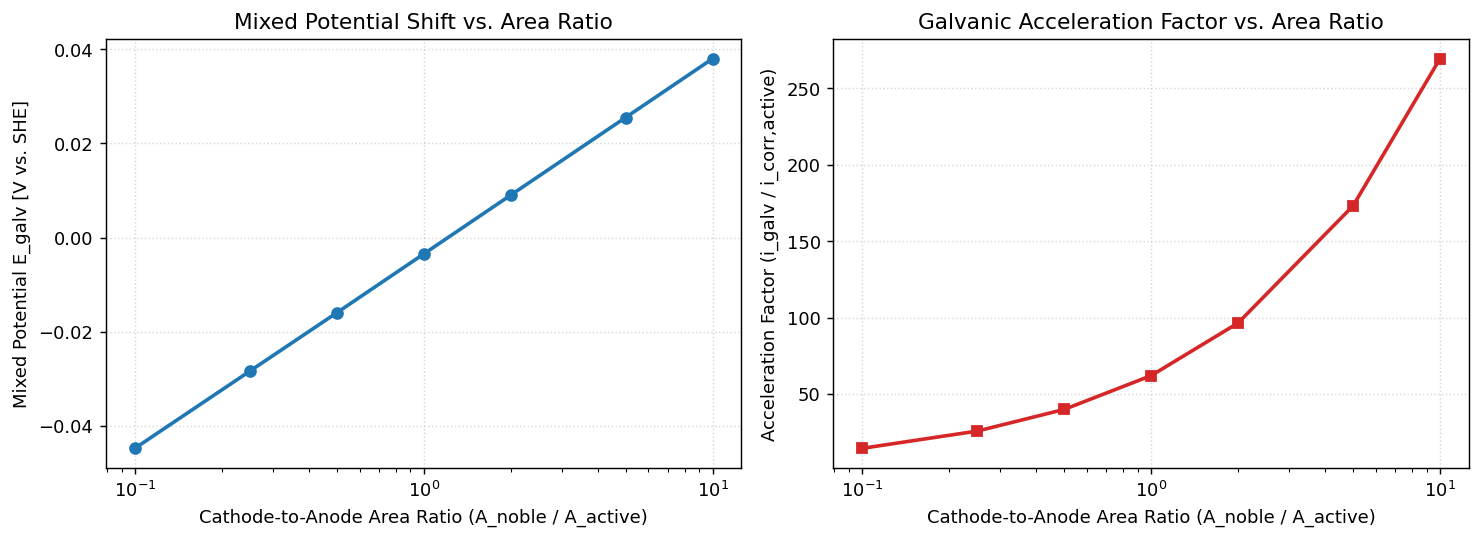

In [3]:
area_ratios = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]
rows = []
for ratio in area_ratios:
    r = solve_galvanic_couple(co_params, cu_params, cathode_to_anode_area_ratio=ratio)
    rows.append({
        "A_noble / A_active": ratio,
        "E_galv (V vs. SHE)": round(r.mixed_potential_V_SHE, 4),
        "i_galv (uA/cm2)": round(r.galvanic_current_density_uA_cm2, 3),
        "Acceleration Factor": round(r.acceleration_factor, 2),
        "Coupled CR_0 (nm/min)": round(r.coupled_cr_nm_min, 4),
        "Residual (uA/cm2)": f"{r.current_balance_residual_uA_cm2:.2e}",
    })

sweep_df = pd.DataFrame(rows)
print(sweep_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
axes[0].semilogx(sweep_df["A_noble / A_active"], sweep_df["E_galv (V vs. SHE)"], marker="o", color="#1f77b4", lw=2)
axes[0].set_xlabel("Cathode-to-Anode Area Ratio (A_noble / A_active)")
axes[0].set_ylabel("Mixed Potential E_galv [V vs. SHE]")
axes[0].set_title("Mixed Potential Shift vs. Area Ratio")
axes[0].grid(True, linestyle=":", alpha=0.5)

axes[1].semilogx(sweep_df["A_noble / A_active"], sweep_df["Acceleration Factor"], marker="s", color="#d62728", lw=2)
axes[1].set_xlabel("Cathode-to-Anode Area Ratio (A_noble / A_active)")
axes[1].set_ylabel("Acceleration Factor (i_galv / i_corr,active)")
axes[1].set_title("Galvanic Acceleration Factor vs. Area Ratio")
axes[1].grid(True, linestyle=":", alpha=0.5)
fig.tight_layout()


## 3. Monte Carlo Uncertainty Propagation from Hybrid ML Predictions

Using the fitted `HybridMLPredictor`, we predict $(E_{\text{corr}}, \log_{10} i_{\text{corr}}, \beta_a, \beta_c)$ with uncertainties for Co and Cu under the same cleaning condition and propagate $N = 500$ draws through the area-weighted mixed-potential solver.


In [4]:
seed_db = HarmonizedDatabase.from_seed()
predictor = HybridMLPredictor(model_family="random_forest", n_estimators=60, random_state=42)
predictor.fit(seed_db)

q_co = MLFeatureQuery(metal="Co", pH=4.0, temperature_C=25.0, oxidizer_type="H2O2", oxidizer_concentration=1.0, acid_type="citric acid", acid_concentration=50.0)
q_cu = MLFeatureQuery(metal="Cu", pH=4.0, temperature_C=25.0, oxidizer_type="H2O2", oxidizer_concentration=1.0, acid_type="citric acid", acid_concentration=50.0)

pred_co = predictor.predict(q_co)
pred_cu = predictor.predict(q_cu)

mc_galv = propagate_galvanic_uncertainty_monte_carlo(
    pred_co,
    pred_cu,
    cathode_to_anode_area_ratio=2.0,
    n_draws=500,
    seed=42,
    material_properties=seed_db.material_properties,
)

summary_df = pd.DataFrame({
    "E_galv (V vs. SHE)": mc_galv.mixed_potential_summary,
    "i_galv (uA/cm2)": mc_galv.galvanic_current_summary,
    "Acceleration Factor": mc_galv.acceleration_factor_summary,
    "Coupled CR_0 (nm/min)": mc_galv.coupled_cr_nm_min_summary,
}).T
print(f"Monte Carlo Galvanic Summary ({mc_galv.active_metal} active vs. {mc_galv.noble_metal} noble, A_noble/A_active=2.0, N={mc_galv.n_draws}):")
print(summary_df.round(4).to_string())


Monte Carlo Galvanic Summary (Co active vs. Cu noble, A_noble/A_active=2.0, N=500):
                            mean        std      p05       p50        p95
E_galv (V vs. SHE)        0.0482     0.0825  -0.0849    0.0464     0.1855
i_galv (uA/cm2)        1755.7598  6631.0492  33.3948  421.7150  5851.8808
Acceleration Factor     110.4312   249.2523   2.5474   26.7410   491.8895
Coupled CR_0 (nm/min)    36.1469   136.5176   0.6875    8.6821   120.4764


## 4. Overlaid Bimetallic Tafel Plot with $E_{\text{galv}}$ Operating Line

We render the overlaid polarization curves for both metals, the area-weighted Noble Metal curve, the solved **Mixed Potential ($E_{\text{galv}}$)** operating line (with 90% Monte Carlo confidence band), and the shift from isolated $i_{\text{corr, active}}$ to coupled $i_{\text{galv}}$.


Rendered overlaid bimetallic Tafel plot with E_galv operating line and 90% MC band.


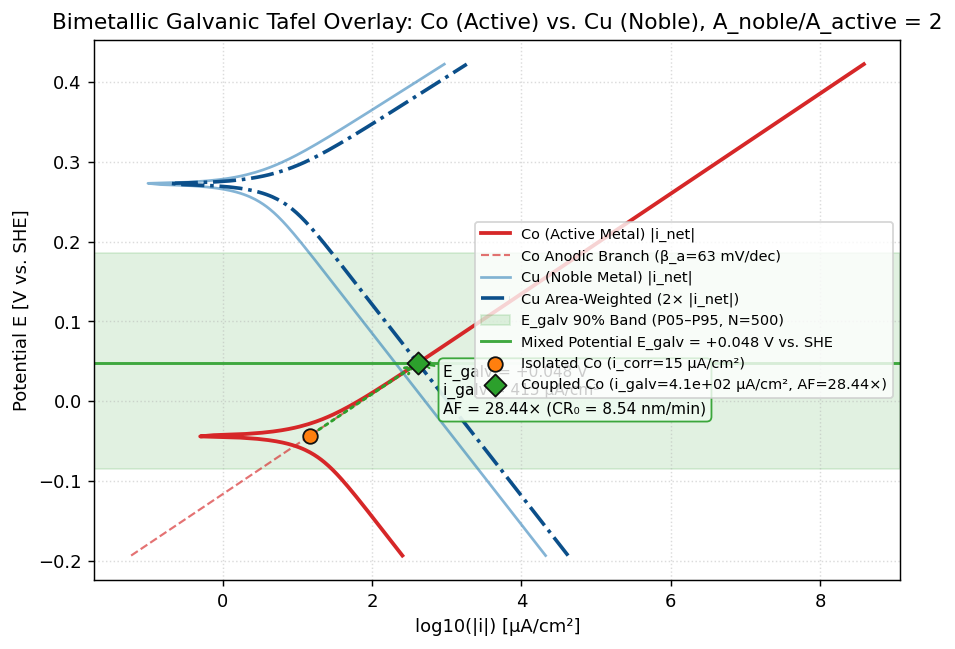

In [5]:
fig, ax = plot_galvanic_tafel_overlay(
    mc_galv.nominal_result,
    mc_result=mc_galv,
    show_area_weighted_noble=True,
)
print("Rendered overlaid bimetallic Tafel plot with E_galv operating line and 90% MC band.")
